# 03 · Ad monetisation

**Question.** How much do ads earn, how well are they delivered, and does early exposure push new players away?
**Answer.** About 38,400 USD of estimated revenue in six weeks, rewarded videos earning twice as much per impression as interstitials. Nothing shows that ads push new players away: at the same level of play, more interstitials go with an equal or slightly higher D1. This is observational; notebook 05 holds the only controlled comparison.
**Method.** Revenue is the ad-network estimate of each impression (table `ads`). Exposure is compared within quartiles of first-day activity (table `day0_q`, `sql/04_ad_exposure_day0.sql`). Intervals are 95% Wilson intervals.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from game_events import config, metrics
from game_events.data import connect_events
from game_events.queries import build_base_tables, build_day0_exposure

con, readable, unreadable = connect_events()
build_base_tables(con)
build_day0_exposure(con)
print(f"{len(readable)} readable files, {len(unreadable)} skipped")

67 readable files, 1 skipped


## 1. Revenue field: completeness and format

In [2]:
con.sql("""
    SELECT COUNT(*)                                                               AS impressions,
           COUNT(*) FILTER (WHERE amount_text IS NULL)                            AS no_revenue_value,
           COUNT(*) FILTER (WHERE amount_text IS NOT NULL AND amount_usd IS NULL) AS unparsable,
           COUNT(*) FILTER (WHERE has_amount_key AND has_value_key)               AS both_keys,
           COUNT(*) FILTER (WHERE amount_text LIKE '%,%' OR amount_text LIKE '%/%') AS non_dot_decimal,
           COUNT(*) FILTER (WHERE amount_usd > 1)                                 AS above_1_usd
    FROM ads
""").show(max_width=200)

┌─────────────┬──────────────────┬────────────┬───────────┬─────────────────┬─────────────┐
│ impressions │ no_revenue_value │ unparsable │ both_keys │ non_dot_decimal │ above_1_usd │
│    int64    │      int64       │   int64    │   int64   │      int64      │    int64    │
├─────────────┼──────────────────┼────────────┼───────────┼─────────────────┼─────────────┤
│     1900860 │                0 │          0 │         0 │          640762 │        1737 │
└─────────────┴──────────────────┴────────────┴───────────┴─────────────────┴─────────────┘



Every impression has a parsable revenue once commas and slashes are read as decimal separators (640,762 values use them). 1,737 impressions are above 1 USD: they are kept, and a capped version is used in the A/B test.

### Which key carries the revenue, and does its level change at the switch?

In [3]:
coverage = con.execute("""
    SELECT day, COUNT(*) AS impressions,
           ROUND(100.0 * COUNT(*) FILTER (WHERE has_value_key)  / COUNT(*), 1) AS pct_value_key,
           ROUND(100.0 * COUNT(*) FILTER (WHERE has_amount_key) / COUNT(*), 1) AS pct_amount_key,
           ROUND(100.0 * COUNT(amount_usd) / COUNT(*), 1)                       AS pct_usable,
           ROUND(AVG(amount_usd) * 1000, 1)                                     AS ecpm_usd
    FROM ads GROUP BY 1 ORDER BY 1
""").df()
coverage

,day,impressions,pct_value_key,pct_amount_key,pct_usable,ecpm_usd
0,2025-02-28,23662,100.0,0.0,100.0,19.9
1,2025-03-01,56150,100.0,0.0,100.0,18.3
2,2025-03-02,57037,100.0,0.0,100.0,20.0
3,2025-03-03,44856,100.0,0.0,100.0,18.6
4,2025-03-04,57015,100.0,0.0,100.0,16.8
5,2025-03-05,58338,100.0,0.0,100.0,16.7
6,2025-03-06,60968,100.0,0.0,100.0,16.7
7,2025-03-07,55160,100.0,0.0,100.0,15.8
8,2025-03-08,54196,100.0,0.0,100.0,18.7
9,2025-03-09,52281,100.0,0.0,100.0,18.1


In [4]:
versions = con.execute("""
    SELECT CAST(ts AS DATE) AS day, user_properties_custom['appVersion'] AS app_version,
           COUNT(DISTINCT user_id) AS players
    FROM events
    WHERE CAST(ts AS DATE) BETWEEN DATE '2025-03-22' AND DATE '2025-04-02'
    GROUP BY 1, 2
""").df()
top_versions = versions.groupby("app_version")["players"].sum().nlargest(6).index
(versions[versions["app_version"].isin(top_versions)]
 .pivot(index="day", columns="app_version", values="players").fillna(0).astype(int))

app_version,0.21.15,0.21.16,0.21.19,0.21.20,0.21.21,0.21.23
day,,,,,,
2025-03-22,72,78,87,248,3639,0
2025-03-23,72,80,86,228,4385,0
2025-03-24,52,48,54,159,3651,0
2025-03-25,49,41,38,161,3969,0
2025-03-26,51,48,30,135,3304,0
2025-03-27,9,8,15,39,1355,4
2025-03-28,63,68,40,146,3361,14
2025-03-29,74,69,61,173,3706,726
2025-03-30,66,67,57,170,2217,3467


## 2. Revenue by format and network

In [5]:
con.sql("""
    SELECT ad_format, COUNT(*) AS impressions, ROUND(SUM(amount_usd), 0) AS revenue_usd,
           ROUND(AVG(amount_usd) * 1000, 1) AS ecpm_usd
    FROM ads GROUP BY 1 ORDER BY 3 DESC
""").show(max_width=200)

con.sql("""
    SELECT ad_source, COUNT(*) AS impressions, ROUND(SUM(amount_usd), 0) AS revenue_usd,
           ROUND(AVG(amount_usd) * 1000, 1) AS ecpm_usd
    FROM ads GROUP BY 1 ORDER BY 3 DESC LIMIT 10
""").show(max_width=200)

┌───────────┬─────────────┬─────────────┬──────────┐
│ ad_format │ impressions │ revenue_usd │ ecpm_usd │
│  varchar  │    int64    │   double    │  double  │
├───────────┼─────────────┼─────────────┼──────────┤
│ REWARDED  │      783442 │     22761.0 │     29.1 │
│ INTER     │     1117418 │     15656.0 │     14.0 │
└───────────┴─────────────┴─────────────┴──────────┘

┌───────────────────┬─────────────┬─────────────┬──────────┐
│     ad_source     │ impressions │ revenue_usd │ ecpm_usd │
│      varchar      │    int64    │   double    │  double  │
├───────────────────┼─────────────┼─────────────┼──────────┤
│ AppLovin          │      985073 │     22136.0 │     22.5 │
│ Mintegral         │      217827 │      5619.0 │     25.8 │
│ Google AdMob      │      255824 │      4153.0 │     16.2 │
│ Facebook          │      104816 │      2617.0 │     25.0 │
│ APPLOVIN_EXCHANGE │       88165 │      1087.0 │     12.3 │
│ Google Ad Manager │       58729 │      1021.0 │     17.4 │
│ Liftoff Monetize

## 3. Ad revenue per active player and per day

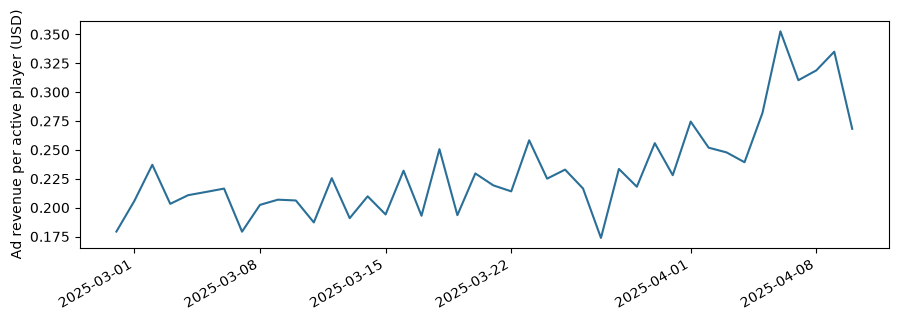

,day,dau,impressions,revenue_usd,revenue_per_active_player,impressions_per_active_player
mean,2025-03-20 12:00:00,3916.881,45258.571,914.69,0.232,11.455
min,2025-02-28 00:00:00,1410.000,13494.000,245.00,0.174,9.020
max,2025-04-10 00:00:00,5001.000,60968.000,1539.00,0.353,13.130


In [6]:
per_player = con.execute("""
    WITH dau AS (SELECT day, COUNT(*) AS dau FROM active_days GROUP BY 1),
         rev AS (SELECT day, SUM(amount_usd) AS revenue, COUNT(*) AS impressions FROM ads GROUP BY 1)
    SELECT d.day, d.dau, r.impressions, ROUND(r.revenue, 0) AS revenue_usd,
           ROUND(r.revenue / d.dau, 4)           AS revenue_per_active_player,
           ROUND(1.0 * r.impressions / d.dau, 2) AS impressions_per_active_player
    FROM dau d JOIN rev r USING (day)
    ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(per_player["day"], per_player["revenue_per_active_player"], color="#2a6f97")
ax.set_ylabel("Ad revenue per active player (USD)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
per_player.describe().round(3).loc[["mean", "min", "max"]]

2025-03-27 is the data gap; 2025-02-28 and 2025-04-10 are partial days.

## 4. Ad delivery

In [7]:
con.sql("""
    SELECT event_name AS lifecycle, event_properties['state'] AS state, COUNT(*) AS events
    FROM events
    WHERE event_name IN ('interstitialLifecycle', 'rvLifecycle')
    GROUP BY 1, 2 ORDER BY 1, 3 DESC
""").show(max_rows=30, max_width=200)

con.sql("""
    SELECT event_name AS lifecycle,
           ROUND(100.0 * COUNT(*) FILTER (WHERE event_properties['state'] = 'AdLoadFailed')
                 / COUNT(*) FILTER (WHERE event_properties['state'] IN ('AdLoaded', 'AdLoadFailed')), 1) AS load_failure_pct
    FROM events
    WHERE event_name IN ('interstitialLifecycle', 'rvLifecycle')
    GROUP BY 1
""").show(max_width=200)

┌───────────────────────┬──────────────────┬─────────┐
│       lifecycle       │      state       │ events  │
│        varchar        │     varchar      │  int64  │
├───────────────────────┼──────────────────┼─────────┤
│ interstitialLifecycle │ AdLoaded         │ 1264795 │
│ interstitialLifecycle │ AdRevenuePaid    │ 1118189 │
│ interstitialLifecycle │ AdHidden         │ 1032392 │
│ interstitialLifecycle │ AdDisplayed      │ 1031316 │
│ interstitialLifecycle │ AdClicked        │  650067 │
│ interstitialLifecycle │ AdLoadFailed     │   32286 │
│ interstitialLifecycle │ AdDisplayFailed  │     560 │
│ rvLifecycle           │ AdLoaded         │  993771 │
│ rvLifecycle           │ AdRevenuePaid    │  783748 │
│ rvLifecycle           │ AdDisplayed      │  751728 │
│ rvLifecycle           │ AdHidden         │  751680 │
│ rvLifecycle           │ AdReceivedReward │  733521 │
│ rvLifecycle           │ AdClicked        │  404531 │
│ rvLifecycle           │ AdLoadFailed     │   40566 │
│ rvLifecy

┌───────────────────────┬──────────────────┐
│       lifecycle       │ load_failure_pct │
│        varchar        │      double      │
├───────────────────────┼──────────────────┤
│ rvLifecycle           │              3.9 │
│ interstitialLifecycle │              2.5 │
└───────────────────────┴──────────────────┘



In [8]:
con.sql("""
    SELECT event_properties['errorInfo'] AS error, COUNT(*) AS events
    FROM events
    WHERE event_name IN ('interstitialLifecycle', 'rvLifecycle')
      AND event_properties['errorInfo'] <> 'no error'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 8
""").show(max_width=250)

┌───────────────────────────────────────────────────────────────────────────────────┬────────┐
│                                       error                                       │ events │
│                                      varchar                                      │ int64  │
├───────────────────────────────────────────────────────────────────────────────────┼────────┤
│ Failed to connect to ms.applvn.com/[::]:443                                       │  16867 │
│ Unable to resolve host "ms.applovin.com": No address associated with hostname     │  15941 │
│ Failed to connect to ms.applvn.com/0.0.0.0:443                                    │  10675 │
│ Failed to connect to ms.applvn.com/127.0.0.1:443                                  │   6483 │
│ NSURLErrorDomain=-1000 : bad URL                                                  │   4013 │
│ NSURLErrorDomain=-1003 : A server with the specified hostname could not be found. │   2780 │
│ Unable to resolve host "ms4.applovin.com": No ad

## 5. First-day exposure and next-day return

Population: new players, cohorts of 2025-03-26 and 2025-03-27 excluded (day 0 or day 1 on the data gap).

In [9]:
con.sql("SELECT COUNT(*) AS players, ROUND(100.0 * AVG(retained_d1::INT), 1) AS d1_pct FROM day0_q").show()
metrics.d1_by_exposure(con, "inter_day0")

┌─────────┬────────┐
│ players │ d1_pct │
│  int64  │ double │
├─────────┼────────┤
│   44170 │   37.0 │
└─────────┴────────┘



,bucket,players,retained,d1_pct,ci_low,ci_high
0,0,10760,2560,23.8,23.0,24.6
1,1-2,9504,2636,27.7,26.8,28.6
2,3-5,7615,2619,34.4,33.3,35.5
3,6+,16291,8528,52.3,51.6,53.1


Players who play longer see more interstitials and also return more: the same comparison follows within groups of similar activity.

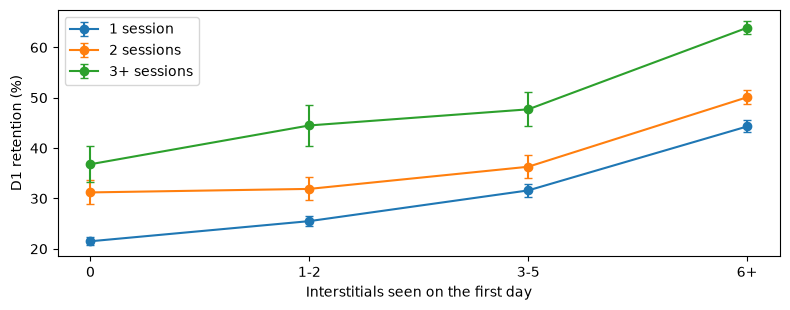

,bucket,players,retained,d1_pct,ci_low,ci_high,day0_sessions
0,0,8618,1856,21.5,20.7,22.4,1 session
1,1-2,7381,1885,25.5,24.6,26.5,1 session
2,3-5,5104,1612,31.6,30.3,32.9,1 session
3,6+,6439,2852,44.3,43.1,45.5,1 session
4,0,1492,465,31.2,28.9,33.6,2 sessions
5,1-2,1534,489,31.9,29.6,34.3,2 sessions
6,3-5,1675,608,36.3,34.0,38.6,2 sessions
7,6+,4502,2257,50.1,48.7,51.6,2 sessions
8,0,650,239,36.8,33.2,40.5,3+ sessions
9,1-2,589,262,44.5,40.5,48.5,3+ sessions


In [10]:
by_sessions = pd.concat([
    metrics.d1_by_exposure(con, "inter_day0", where=f"sessions_day0 {cond}").assign(day0_sessions=label)
    for label, cond in [("1 session", "= 1"), ("2 sessions", "= 2"), ("3+ sessions", ">= 3")]
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 3.2))
for label, g in by_sessions.groupby("day0_sessions"):
    g = g[g["players"] >= 200]                      # smaller cells give intervals too wide to read
    ax.errorbar(g["bucket"], g["d1_pct"], yerr=[g["d1_pct"] - g["ci_low"], g["ci_high"] - g["d1_pct"]],
                marker="o", capsize=3, label=label)
ax.set_xlabel("Interstitials seen on the first day")
ax.set_ylabel("D1 retention (%)")
ax.legend()
plt.tight_layout()
plt.show()
by_sessions

Rewarded videos are chosen by the player: they reflect interest rather than annoyance.

In [11]:
metrics.d1_by_exposure(con, "rewarded_day0")

,bucket,players,retained,d1_pct,ci_low,ci_high
0,0,14899,4321,29.0,28.3,29.7
1,1-2,11603,3805,32.8,31.9,33.7
2,3-5,7371,3014,40.9,39.8,42.0
3,6+,10297,5203,50.5,49.6,51.5


### Within quartiles of first-day activity

Activity = gameplay events on day 0. Quartile 1 is the least active group.

In [12]:
by_play = pd.concat([
    metrics.d1_by_exposure(con, "inter_day0", where=f"play_quartile = {q}").assign(play_quartile=q)
    for q in (1, 2, 3, 4)
], ignore_index=True)
by_play

,bucket,players,retained,d1_pct,ci_low,ci_high,play_quartile
0,0,7690,1521,19.8,18.9,20.7,1
1,1-2,3306,767,23.2,21.8,24.7,1
2,3-5,45,12,26.7,16.0,41.0,1
3,6+,2,1,50.0,9.5,90.5,1
4,0,1712,459,26.8,24.8,29.0,2
5,1-2,5211,1437,27.6,26.4,28.8,2
6,3-5,4003,1251,31.3,29.8,32.7,2
7,6+,117,39,33.3,25.4,42.3,2
8,0,847,315,37.2,34.0,40.5,3
9,1-2,718,281,39.1,35.6,42.8,3


## Findings

- **Where the revenue is stored.** The ad revenue of an impression is under the key `value` until 2025-03-28 (100% of impressions), under both keys on 2025-03-29 (85.3% `value`, 14.7% `amount`) and under `amount` from 2025-03-30 (98.5%, then about 100%). With `COALESCE(amount, value)`, every one of the 1,900,860 impressions has a usable revenue, on all 42 days.
- **Revenue.** About 38,400 USD of estimated ad revenue over six weeks. Rewarded videos bring 22,761 USD from 41% of impressions (eCPM, the revenue per 1,000 impressions, is 29.1 USD); interstitials bring 15,656 USD (eCPM 14.0). By network, AppLovin is the largest (22,136 USD, eCPM 22.5); Mintegral (25.8) and Facebook (25.0) pay more per impression; AdMob (16.2), Liftoff (10.1) and Pangle (7.3) pay less.
- **Revenue per active player.** On average 0.23 USD per active player per day (range 0.17 to 0.35), with 11.5 impressions per active player per day (range 9.0 to 13.1). These are estimates reported by the ad networks, not cash received.
- **A shift in level after the rename.** eCPM is about 27% higher from 2025-03-31 than before 2025-03-29, in both formats (rewarded 27.0 to 34.1 USD, interstitial 12.9 to 16.6 USD). It may be real (new app version 0.21.23, new ad configuration) or due to a change in how the value is measured; the data do not say which. Do not compare revenue before and after as if it were one series.
- **Outliers.** 1,737 impressions are above 1 USD each and add up to about 2,700 USD (about 7% of revenue); a version of the revenue capped at 1 USD per impression is given for the tests.
- **Delivery.** Load failures are 3.9% for rewarded videos and 2.5% for interstitials. The most frequent errors are network ones (host not resolved, connection to `127.0.0.1` or `0.0.0.0`); the latter pattern could come from DNS filtering or ad blockers (not verified).
- **Early exposure and retention.** Among 44,170 new players, D1 rises with first-day interstitials: 23.8% with none, 27.7% with 1 to 2, 34.4% with 3 to 5 and 52.3% with 6 or more. Most of this gradient is play volume: when players are split into four groups by first-day gameplay events, D1 goes from 19.8% to 51.9% between the least and most active groups with no ads at all, while inside a group the difference between none and 6 or more interstitials is about 3 to 7 points (51.9% to 58.6% in the most active group; 37.2% to 42.8% in the third). Rewarded ads show the same pattern before controls (29.0% with none, 50.5% with 6 or more).
- **What this does and does not say.** Nothing in these data shows that ads push new players away: within comparable play levels, more ads go with equal or slightly higher D1. This does not prove ads help retention; exposure still reflects how long a player stays, and some cells are small (2 players with 6 or more ads in the least active group). The only controlled comparison is the experiment of notebook 05.
- **The 2025-03-27 gap is not specific to one app version.** On that day players fall by about 60% in every version (1,355 against about 3,500 in 0.21.21; 9 against about 50 in 0.21.15), so a bug of the new version does not explain it. Version 0.21.23 first appears that day (4 players), which may be a coincidence; the cause remains unknown.

**Limits.**
- Revenue is an estimate reported by the ad networks, not cash received.
- Revenue before and after 2025-03-29 may not be comparable (see above).
- Exposure and retention are both driven by how much a player plays; the controls reduce this effect but do not remove it.
- Cohorts of 2025-03-26 and 2025-03-27 are excluded because of the data gap.